In [2]:
import pandas as pd, matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score

df = pd.read_csv('Mall_Customers.csv')
df.iloc[:, 1] = LabelEncoder().fit_transform(df.iloc[:, 1])   # Gender -> 0/1
X = StandardScaler().fit_transform(df.iloc[:, [3, 4]])         # Income, Spending Score

df.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,1,19,15,39
1,2,1,21,15,81
2,3,0,20,16,6
3,4,0,23,16,77
4,5,0,31,17,40


C:\Users\Asus\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\Asus\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\Asus\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\Asus\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^

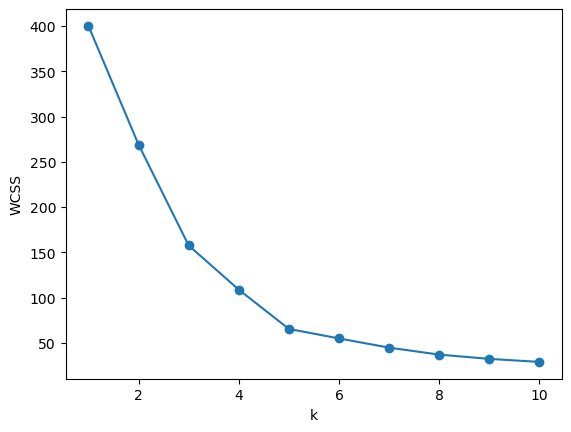

KMeans: 0.5546571631111091  Hierarchical: 0.5538089226688662


C:\Users\Asus\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


In [3]:
plt.plot(range(1, 11), [KMeans(n_clusters=k, n_init=10, random_state=1).fit(X).inertia_ for k in range(1, 11)], 'o-')
plt.xlabel('k'); plt.ylabel('WCSS'); plt.show()

km = KMeans(n_clusters=5, n_init=10, random_state=1).fit_predict(X)
hc = AgglomerativeClustering(n_clusters=5).fit_predict(X)
print('KMeans:', silhouette_score(X, km), ' Hierarchical:', silhouette_score(X, hc))

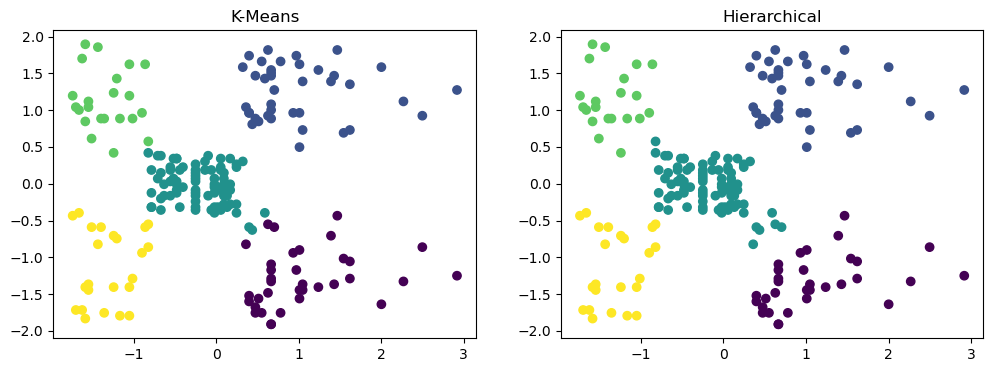

,Annual Income (k$),Spending Score (1-100)
Cluster,,
0,88.200000,17.114286
1,86.538462,82.128205
2,55.296296,49.518519
3,25.727273,79.363636
4,26.304348,20.913043


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(X[:, 0], X[:, 1], c=km); ax[0].set_title('K-Means')
ax[1].scatter(X[:, 0], X[:, 1], c=hc); ax[1].set_title('Hierarchical')
plt.show()

df['Cluster'] = km
df.groupby('Cluster')[list(df.columns[3:5])].mean()